## Prepare for analysis - get models

**Load modules**

In [1]:
import requests
import reframed
import pandas as pd
import warnings

import matplotlib.pyplot as plt
from os import listdir
import json
import numpy as np

In [2]:
import sys

sys.path.append("../functions/")
from minimal_medium import minimal_medium

#### Run this the first time you run the script (for gut microbiome)

### E. coli auxotrophs (Guillen et al. 2021) 

**Load model**

In [3]:
# Load curated model from Bernstein et al (2023)
url = "https://github.com/dbernste/E_coli_GEM_validation/raw/refs/heads/main/Analysis/iML1515_model_adjusted_all_corrections.xml"
response = requests.get(url)

if response.status_code == 200:
    with open("../models/Guillen2021/iML1515.xml", "wb") as f:
        f.write(response.content)
else:
    print("Failed to download the file. Check the URL.")

model_ecoli = reframed.load_cbmodel("../models/Guillen2021/iML1515.xml")

Map gene id to name

In [4]:
id2name = {}
for gene in model_ecoli.genes:
    id2name[gene] = model_ecoli.genes[gene].name

id2name_ser = pd.Series(id2name)
id2name_ser.name="name"
id2name_ser.index.name="id"
id2name_ser.to_csv("../data/Guillen2021/generated/gene_id2name.tsv",sep="\t")

**Experimental relative abundance from Guillen et al (2021)**

In [5]:
# NB! yhhK in data == panZ in paper
relative_abundance = pd.read_csv("../data/Guillen2021/relative_abundance.csv",index_col=0)
relative_abundance.index =relative_abundance.index.map(lambda x:x if x!="yhhK" else "panZ")

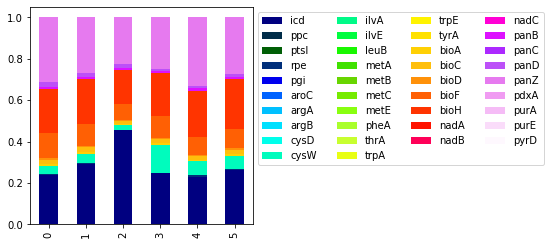

In [6]:
ax = relative_abundance.T.plot.bar(stacked=True,cmap="gist_ncar",figsize=(4,4))

plt.legend(loc="upper left", ncol=len(relative_abundance.index)/8,bbox_to_anchor=(1,1))

In [7]:
relative_abundance.T.mean().sort_values(ascending=False).head(10)

icd     0.287848
panZ    0.276678
bioH    0.211130
bioF    0.098526
cysW    0.062219
bioC    0.020200
panD    0.015948
panB    0.009927
bioA    0.007043
bioD    0.005411
dtype: float64

**Generate models for each E.coli strain**

NB! Removing the gene for panD instead because panZ is a regulatory protein. Also remove cysZ for cysW mutant to get desired behavior.

In [8]:
name2id_38 = id2name_ser[id2name_ser.isin(relative_abundance.index)]\
                .reset_index()\
                .set_index("name")["id"]\
                .to_dict()

In [9]:
# additional details for special cases
name2id_38["panZ"]=name2id_38["panD"] # panZ is a regulatory protein for panD
model_ecoli.reactions.R_SULabcpp.gpr.proteins.pop(1) # Remove molybdate genes
model_ecoli.add_reaction_from_str("R_PNTOtex2: M_pnto__R_c --> M_pnto__R_e")
model_ecoli.add_reaction_from_str("R_BTNtex2: M_btn_c --> M_btn_e")
model_ecoli.update()  

# make models
ecoli_models = {}

for name,id_ in name2id_38.items():
    if name=="cysW": # Special case: cysW - also remove cysZ
        ecoli_models[name] = reframed.hard_knockout(model_ecoli,[id_,"G_b2413"],
                                                    rename="mutant_"+name) #remove cysZ gene
    else: 
        ecoli_models[name] = reframed.hard_knockout(model_ecoli,[id_],rename="mutant_"+name)

In [10]:
gene1 = "panD"
gene2 = "panD"
for rxn in ecoli_models[gene1].get_reactions_by_gene(name2id_38[gene2]):
    lb = ecoli_models[gene1].reactions[rxn].lb
    ub = ecoli_models[gene1].reactions[rxn].ub
    print(f"{rxn} flux constrained for {gene1} reactions: {(lb,ub)}")

gene1 = "panD"
gene2 = "icd"
for rxn in ecoli_models[gene1].get_reactions_by_gene(name2id_38[gene2]):
    lb = ecoli_models[gene1].reactions[rxn].lb
    ub = ecoli_models[gene1].reactions[rxn].ub
    print(f"{rxn} flux NOT constrained for {gene2}: {(lb,ub)}")

R_ASP1DC flux constrained for panD reactions: (0, 0)
R_ICDHyr flux NOT constrained for icd: (-inf, inf)


**Save models**

*All models*

In [11]:
for name,model in ecoli_models.items():
    reframed.save_cbmodel(model,"../models/Guillen2021/strains/"+model.id+".xml")

*Top 7 members*

In [12]:
ra_mean = relative_abundance.T.mean()
top7_members = ra_mean[ra_mean>0.01].index

for member in top7_members:
    model = ecoli_models[member]
    reframed.save_cbmodel(model,"../models/Guillen2021/top_7_strains/"+model.id+".xml")

### Gut microbiome (Venturelli et al. 2018) 

Models for relevant species were collected from the AGORA2 database ([sbml_files_fixed](https://vmh.life/files/reconstructions/AGORA2/version2.01/))

**Load models**

In [13]:
models = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore')
    for path in listdir("../models/Venturelli2018/species_used/"):
        models[path[:-4]] = reframed.load_cbmodel("../models/Venturelli2018/species_used/"+path,exchange_detection="R_EX_(?!biomass__40__e__41__)")
    

In [14]:
with open('../data/Venturelli2018/generated/metname2metanetx.json') as json_file:
    metname2metanetx = json.load(json_file)

with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [15]:
len(set(metname2metanetx.keys()).intersection(set(metid2metname.values())))

58

In [16]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Remove O2 metabolites - because of anaerobic environment**

In [17]:
models_gut = {}

for name,model in models.items():
    if "M_o2__91__e__93__" in model.metabolites:
        print(name)
        model.remove_metabolite("M_o2__91__e__93__")
    model.update()
    models_gut[name]=model
    reframed.save_cbmodel(model,"../models/Venturelli2018/species_used_noO2/"+name+".xml")


Bacteroides_uniformis_ATCC_8492
Bacteroides_vulgatus_ATCC_8482
Collinsella_aerofaciens_ATCC_25986
Faecalibacterium_prausnitzii_A2_165
Eggerthella_lenta_DSM_2243
Prevotella_copri_CB7_DSM_18205
Clostridium_hiranonis_TO_931_DSM_13275
Eubacterium_rectale_ATCC_33656
Desulfovibrio_piger_ATCC_29098
Bacteroides_ovatus_ATCC_8483
Bacteroides_thetaiotaomicron_VPI_5482
Blautia_hydrogenotrophica_DSM_10507


## Prepare for analysis - make media

In [18]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")

### E.coli auxotrophs

The medium used in the study was M9 medium, which is already defined.

In [19]:
media_db[media_db.medium=="M9"].to_csv("../data/Guillen2021/generated/media_db.tsv",sep="\t",index=None)

### Gut microbiome models

**Gather data**

*Get compounds for LB medium*

*Translate to BiGG*

In [20]:
mets_id_ag = []
mets_id_bigg = []
ex_rxns_ag = []
for model in models.values():
    for rxn in model.get_exchange_reactions():
        if "R_EX_" not in rxn:
            continue
        met_id_ag = model.reactions[rxn].get_substrates()[0]
        mets_id_ag.append(met_id_ag)
        met_id_bigg = model.metabolites[met_id_ag].metadata["XMLAnnotation"].split("bigg.metabolite/")[1].split("\"")[0]
        mets_id_bigg.append(met_id_bigg)
        ex_rxns_ag.append(rxn)
    
met2ex = dict(zip(mets_id_bigg,ex_rxns_ag))

**Check growth on LB medium**

In [21]:
compounds = media_db[media_db.medium=="LB[-O2]"].compound.values

lb_env = reframed.Environment.from_reactions([met2ex[met] for met in compounds if met in met2ex.keys()])

In [22]:
for model_id,model in models.items():
    lb_env.apply(model,inplace=True,exclusive=True,warning=False)
    sol = reframed.FBA(model)
    print(f"{model_id}: {sol.fobj}")

Bacteroides_uniformis_ATCC_8492: 1.6752817917917833
Bacteroides_vulgatus_ATCC_8482: 0.0
Collinsella_aerofaciens_ATCC_25986: 0.0
Faecalibacterium_prausnitzii_A2_165: 0.0
Eggerthella_lenta_DSM_2243: 0.0
Prevotella_copri_CB7_DSM_18205: 1.3630362595658083
Clostridium_hiranonis_TO_931_DSM_13275: 0.0
Eubacterium_rectale_ATCC_33656: 1.122357292219717
Desulfovibrio_piger_ATCC_29098: 0.0
Bacteroides_ovatus_ATCC_8483: 1.8542085538811053
Bacteroides_thetaiotaomicron_VPI_5482: 0.0
Blautia_hydrogenotrophica_DSM_10507: 0.0


**Defining a media where all members can grow (NB: Might change slightly for each run)**

In [23]:
rxns = ["R_EX_"+met[2:].replace("91","40").replace("93","41") for met in metid2metname.keys() if "__e__" in met]

# Following reactions added based on media composition: http://www.oxoid.com/UK/BLUE/prod_detail/prod_detail.asp?pr=CM0957
rxns.append("R_EX_malt__40__e__41__")
rxns.append("R_EX_cellb__40__e__41__")
rxns.append("R_EX_succ__40__e__41__")
rxns.append("R_EX_mqn8__40__e__41__")
rxns.append("R_EX_arg_L__40__e__41__")
rxns.append("R_EX_cys_L__40__e__41__")
rxns.append("R_EX_pyr__40__e__41__")


# Amino acids in peptone: https://www.usbio.net/media/P3300/peptone
rxns.append("R_EX_asn_L__40__e__41__")
rxns.append("R_EX_ala_L__91__e__93__")
rxns.append("R_EX_arg_L__91__e__93__")
rxns.append("R_EX_asp_L__40__e__41__")
rxns.append("R_EX_cys_L__40__e__41__")
rxns.append("R_EX_gly__40__e__41__")
rxns.append("R_EX_his_L__40__e__41__")
rxns.append("R_EX_ile_L__40__e__41__")
rxns.append("R_EX_glu_L__40__e__41__")
rxns.append("R_EX_leu_L__40__e__41__")
rxns.append("R_EX_lys_L__40__e__41__")
rxns.append("R_EX_met_L__40__e__41__")
rxns.append("R_EX_phe_L__40__e__41__")
rxns.append("R_EX_pro_L__40__e__41__")
rxns.append("R_EX_ser_L__40__e__41__")
rxns.append("R_EX_thr_L__40__e__41__")
rxns.append("R_EX_trp_L__40__e__41__")
rxns.append("R_EX_tyr_L__40__e__41__")
rxns.append("R_EX_val_L__40__e__41__")
rxns.append("R_EX_gln_L__40__e__41__")

# Nucleotides from yeast extract https://pmc.ncbi.nlm.nih.gov/articles/PMC9998214/
rxns.append("R_EX_ade__40__e__41__")
rxns.append("R_EX_csn__40__e__41__")
rxns.append("R_EX_gua__40__e__41__")
rxns.append("R_EX_thym__40__e__41__")
rxns.append("R_EX_ura__40__e__41__")

# Other important compounds https://pmc.ncbi.nlm.nih.gov/articles/PMC9998214/
rxns.append("R_EX_thm__40__e__41__")
rxns.append("R_EX_ribflv__40__e__41__")
rxns.append("R_EX_nac__40__e__41__")
rxns.append("R_EX_ncam__40__e__41__")
rxns.append("R_EX_pnto_R__40__e__41__")
rxns.append("R_EX_pydxn_R__40__e__41__")
rxns.append("R_EX_btn__40__e__41__")
rxns.append("R_EX_fol__40__e__41__")
rxns.append("R_EX_cbl1__40__e__41__")

#rxns.append("R_EX_gam26s__40__e__41__") # For peptidoglucan

missing_total = []
sol_count_dfs = {}
for model_id,model in models.items():
    print(f"Started finding medium for {model_id}")
    lb_env.apply(model,inplace=True,exclusive=True,warning=False)
    sol = reframed.FBA(model)
    
    if sol.fobj>1e-6:
        print(f"\t No need for extra compounds for {model_id}, growth: {sol.fobj}")
    
        print("\n")
        continue
    else:
        print(f"\t {model_id} cannot grow: {sol.fobj}")
    
    # Define complete medium for model - exclude some reactions
    env_complete = reframed.Environment.complete(model)
    env_complete.apply(model,inplace=True,exclusive=True,warning=False)

    rxns_complete = env_complete.keys()
    rxns_complete = list(set([e for e in rxns_complete if ("R_DM" not in e) and ("_acald_" not in e)])) #("R_DM" not in e) & ("sink" not in e)]
    rxns_exclude = ["R_EX_h2__40__e__41__","R_EX_h2s__40__e__41__","R_EX_o2__40__e__41__"] # not possible without including h2!!
    rxns_complete = [rxn for rxn in rxns_complete if rxn not in rxns_exclude]
    
    # Run minimal medium and process results
    solutions = minimal_medium(model,exchange_reactions=list(rxns_complete),preferred_reactions=rxns,min_growth=0.1,n_solutions=1000,use_pool=True,min_mass_weight=True)

    for sol in solutions[1]:
        print(f"\t Minimal media fobj: {sol.fobj}")
        break
        
    sol_count = dict()
    for sol in solutions[0]:
        for rxn in sol:
            if rxn in sol_count.keys():
                sol_count[rxn]+=1
            else:
                sol_count[rxn]=1
    
    sol_count_df = pd.Series(sol_count).sort_values(ascending=False)
    sol_count_dfs[model_id]=sol_count_df
    
    # test growth on new medium and adjust cutoff to minimize added compounds
    cutoff_values = np.linspace(0,1000,11)[::-1] # going in reverse order from 1000 to 0
    
    for cutoff in cutoff_values:
        missing = list((set(sol_count_df[sol_count_df>=cutoff].index)-set(lb_env.keys())))

        lb_extended = [met2ex[met] for met in compounds if met in met2ex.keys()]
        lb_extended.extend(missing)
        lb_extended.extend(rxns)
        lb_extended = list(set(lb_extended))
        env_lb_extend = reframed.Environment.from_reactions(lb_extended)
        env_lb_extend.apply(model,inplace=True,exclusive=True,warning=False)
        sol = reframed.FBA(model)
        
        if sol.fobj>1e-6:
            print(f"\t {model_id} growth at cutoff {cutoff}, growth: {sol.values['R_EX_biomass__40__e__41__']}\n")
            break
        else:
            print(f"\t No solution for cutoff: {cutoff}")
            if cutoff==0:
                raise Exception("\t There should be a solution when all compounds are included...")
            
    
    # Add missing reactions
    missing_total.extend(missing)

add2lb = list(set(missing_total))

Started finding medium for Bacteroides_uniformis_ATCC_8492
	 No need for extra compounds for Bacteroides_uniformis_ATCC_8492, growth: 1.6752817917917833


Started finding medium for Bacteroides_vulgatus_ATCC_8482
	 Bacteroides_vulgatus_ATCC_8482 cannot grow: 0.0


/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/core/elements.py:62: UserWarning: Atomic weight not listed for elements: {'X'}
  warn(f"Atomic weight not listed for elements: {missing}")


	 Minimal media fobj: 344423.70989099174
	 Bacteroides_vulgatus_ATCC_8482 growth at cutoff 1000.0, growth: 5.644924810714796

Started finding medium for Collinsella_aerofaciens_ATCC_25986
	 Collinsella_aerofaciens_ATCC_25986 cannot grow: 0.0
	 Minimal media fobj: 107604.268
	 No solution for cutoff: 1000.0
	 No solution for cutoff: 900.0
	 No solution for cutoff: 800.0
	 No solution for cutoff: 700.0
	 No solution for cutoff: 600.0
	 Collinsella_aerofaciens_ATCC_25986 growth at cutoff 500.0, growth: 2.2707258601149074

Started finding medium for Faecalibacterium_prausnitzii_A2_165
	 Faecalibacterium_prausnitzii_A2_165 cannot grow: 0.0
	 Minimal media fobj: 87629.95499999999
	 Faecalibacterium_prausnitzii_A2_165 growth at cutoff 1000.0, growth: 2.647027307088048

Started finding medium for Eggerthella_lenta_DSM_2243
	 Eggerthella_lenta_DSM_2243 cannot grow: 0.0
	 Minimal media fobj: 406146.4029
	 Eggerthella_lenta_DSM_2243 growth at cutoff 1000.0, growth: 1.257342474031504

Started find

*Metabolites to add*

In [24]:
print(add2lb)

['R_EX_sheme__40__e__41__', 'R_EX_26dap_M__40__e__41__', 'R_EX_lanost__40__e__41__', 'R_EX_q8__40__e__41__', 'R_EX_malt__40__e__41__', 'R_EX_2obut__40__e__41__', 'R_EX_glyc__40__e__41__', 'R_EX_phenol__40__e__41__', 'R_EX_cit__40__e__41__', 'R_EX_cgly__40__e__41__', 'R_EX_nmn__40__e__41__', 'R_EX_glyc3p__40__e__41__', 'R_EX_ptrc__40__e__41__', 'R_EX_arab_D__40__e__41__', 'R_EX_gln_L__40__e__41__', 'R_EX_spmd__40__e__41__', 'R_EX_cytd__40__e__41__']


**Confirm growth on new medium**

In [25]:
lb_extended = [met2ex[met] for met in compounds if met in met2ex.keys()]
lb_extended.extend(add2lb)
lb_extended.extend(rxns)

lb_extended = list(set(lb_extended))

env_lb_extend = reframed.Environment.from_reactions(lb_extended)

for model_id,model in models.items():
    env_lb_extend.apply(model,inplace=True,exclusive=True,warning=False)
    sol = reframed.pFBA(model)
    print(f"{model_id}: {sol.values['R_EX_biomass__40__e__41__']}")


Bacteroides_uniformis_ATCC_8492: 6.543258566695846
Bacteroides_vulgatus_ATCC_8482: 5.964670828393609
Collinsella_aerofaciens_ATCC_25986: 2.5140179165557894
Faecalibacterium_prausnitzii_A2_165: 2.7228479765351676
Eggerthella_lenta_DSM_2243: 1.2573424740315045
Prevotella_copri_CB7_DSM_18205: 5.343549297386246
Clostridium_hiranonis_TO_931_DSM_13275: 0.7601605197088028
Eubacterium_rectale_ATCC_33656: 3.829380200989084
Desulfovibrio_piger_ATCC_29098: 1.024165569204372
Bacteroides_ovatus_ATCC_8483: 7.933896047555076
Bacteroides_thetaiotaomicron_VPI_5482: 6.496346140851836
Blautia_hydrogenotrophica_DSM_10507: 2.8239206162429213


In [26]:
medium_rxns = [rxn.replace("40","91").replace("41","93") for rxn in env_lb_extend.keys()]
medium_name = ["LB_extend" for rxn in medium_rxns]
media_db_gut = pd.DataFrame([medium_name,medium_rxns]).T
media_db_gut.columns=["medium","compound"]

media_db_gut.to_csv("../data/Venturelli2018/generated/media_db.tsv",sep="\t",index=False)

### Maximum import rates

**Specific growth rate $\mu$**

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 1:20 => the cells increase in density by 21 times)

$$
X_1/X_0 = 21 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(21)}{t}
$$


**Substrate uptake rate $v_s$**
$$
\frac{dS}{dt} = X_0 e^{\mu t} v_s
$$

We assume that all the substrate is used between each transfer: $S_{t=end}=0$, $S_0$ is defined (and dependent on the susbtrate).

$$
dS = X_{t=0} e^{\mu t} v_s dt
$$

becomes...

$$
S_{t=end}-S_{t=0}  = X_0 * v_s * [\frac{e^{\mu t}}{\mu}]^{t=end}_{t=0}
$$

which becomes...
$$
-S_{t=0} =X_0 * v_s * \frac{e^{\mu t}-1}{\mu}
$$

from previously we have defined: $21 = e^{\mu t}$. This means that $v_s$ can be defined as...

$$
v_s = -\frac{S_{t=0} \mu}{X_{t=0} 20}
$$

In [27]:
import molmass

In [28]:

conc = {"M_malt__91__e__93__":1, #g/L
        "M_cellb__91__e__93__":1, #g/L
        "M_pyr__91__e__93__":1, #g/L
        "M_succ__91__e__93__":0.5, #g/L
       }


molarmasses = {}
mets = conc.keys()

for met in mets:
    for model in models_gut.values():
        if met in model.metabolites:
            formula = model.metabolites[met].metadata["FORMULA"]
            molarmass = molmass.Formula(formula).mass
            molarmasses[met]=molarmass
            break
        


In [29]:
molarmasses

{'M_malt__91__e__93__': 342.297037,
 'M_cellb__91__e__93__': 342.297037,
 'M_pyr__91__e__93__': 87.054258,
 'M_succ__91__e__93__': 116.07234399999999}

In [30]:
mmolars = {}
for met,conc_i in conc.items():
    mmolars[met] = conc_i*1000/molarmasses[met]
    

In [31]:
mmolars

{'M_malt__91__e__93__': 2.9214392527739,
 'M_cellb__91__e__93__': 2.9214392527739,
 'M_pyr__91__e__93__': 11.487088891160269,
 'M_succ__91__e__93__': 4.307658334185102}

In [32]:
(2.9*0.13)/(0.01*0.3*12*20/21)

10.995833333333334

In [33]:
rxns = [met2ex[met].replace("40","91").replace("41","93") for met in media_db[media_db.medium=="LB[-O2]"].compound.values if met in met2ex.keys()]

media_db_gut["bound"]=10
media_db_gut.loc[media_db_gut.compound.isin(rxns),"bound"]=50

In [34]:
media_db_gut.to_csv("../data/Venturelli2018/generated/media_db_bounds.tsv",sep="\t",index=False)

In [35]:
media_db_gut

,medium,compound,bound
0,LB_extend,R_EX_glu_L__91__e__93__,50
1,LB_extend,R_EX_lys_L__91__e__93__,50
2,LB_extend,R_EX_taur__91__e__93__,10
3,LB_extend,R_EX_his_L__91__e__93__,50
4,LB_extend,R_EX_nh4__91__e__93__,50
...,...,...,...
93,LB_extend,R_EX_cytd__91__e__93__,10
94,LB_extend,R_EX_asn_L__91__e__93__,10
95,LB_extend,R_EX_4hpro_LT__91__e__93__,10
96,LB_extend,R_EX_arab_D__91__e__93__,10


In [36]:
"R_EX_xan__91__e__93__" in media_db_gut.compound.values

True

In [37]:
media_smetana =  pd.read_csv("../data/Venturelli2018/generated/media_db_smetana.tsv",sep="\t")

In [38]:
rxns_smetana = set(["R_EX_"+met+"__91__e__93__" for met in media_smetana.compound.values])

In [39]:
rxns_gut = set(media_db_gut.compound.values)

In [40]:
rxns_smetana-rxns_gut

{'R_EX_for__91__e__93__',
 'R_EX_glycys__91__e__93__',
 'R_EX_metala__91__e__93__'}

In [41]:
rxns_old = set(pd.read_csv("/Users/idunmariaburgos/Desktop/media_db_lb_extend.tsv",sep="\t").compound.values)

In [42]:
rxns_old-rxns_gut

{'R_EX_ac__91__e__93__',
 'R_EX_gam26s__91__e__93__',
 'R_EX_glycys__91__e__93__',
 'R_EX_rbflvrd__91__e__93__'}

In [43]:
for model in models_gut.values():
    if "R_EX_ribflv__40__e__41__" in model.reactions:
        print(model.id)

M_Collinsella_aerofaciens_ATCC_25986
M_Faecalibacterium_prausnitzii_A2_165
M_Eggerthella_lenta_DSM_2243
M_Clostridium_hiranonis_TO_931_DSM_13275
M_Eubacterium_rectale_ATCC_33656
M_Blautia_hydrogenotrophica_DSM_10507


In [44]:
for model in models_gut.values():
    if "R_EX_rbflvrd__40__e__41__" in model.reactions:
        print(model.id)

M_Faecalibacterium_prausnitzii_A2_165
M_Eubacterium_rectale_ATCC_33656


In [45]:
el_test = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_abundance/EL_minus.tsv",sep="\t")

In [46]:
el_rxns = set([met.replace("M_","R_EX_") for met in el_test[el_test.donor=="environment"].compound.unique()])

In [47]:
el_rxns-rxns_gut

{'R_EX_26dap_R_EX__91__e__93__',
 'R_EX_gam26s__91__e__93__',
 'R_EX_glycys__91__e__93__'}

In [48]:
el_test_env = el_test[el_test.donor=="environment"]
el_test_env[el_test_env.compound.isin([rxn.replace("R_EX_","M_") for rxn in el_rxns-rxns_gut])].groupby("compound").sum()[["mass_rate","rate","frequency"]]

,mass_rate,rate,frequency
compound,,,
M_26dap_M__91__e__93__,0.000848,0.004456,2.0
M_gam26s__91__e__93__,0.003331,0.009875,1.3
M_glycys__91__e__93__,0.000528,0.002964,2.0


In [49]:
el_test_env[el_test_env.compound.isin([rxn.replace("R_EX_","M_") for rxn in el_rxns-rxns_gut])][["compound","frequency"]].groupby("compound").mean()

,frequency
compound,
M_26dap_M__91__e__93__,1.00
M_gam26s__91__e__93__,0.65
M_glycys__91__e__93__,0.50


In [50]:
el_test_env[el_test_env.compound.isin([rxn.replace("R_EX_","M_") for rxn in el_rxns-rxns_gut])].groupby(["receiver","compound"]).sum()[["mass_rate","rate","frequency"]]

mass_rate  \
receiver                              compound                               
Bacteroides_ovatus_ATCC_8483          M_gam26s__91__e__93__   3.324525e-03   
Bacteroides_thetaiotaomicron_VPI_5482 M_gam26s__91__e__93__   6.190643e-06   
Bacteroides_vulgatus_ATCC_8482        M_26dap_M__91__e__93__  6.711075e-04   
Blautia_hydrogenotrophica_DSM_10507   M_glycys__91__e__93__   4.029704e-07   
Collinsella_aerofaciens_ATCC_25986    M_26dap_M__91__e__93__  1.764769e-04   
                                      M_glycys__91__e__93__   4.474617e-05   
Desulfovibrio_piger_ATCC_29098        M_glycys__91__e__93__   1.657966e-06   
Faecalibacterium_prausnitzii_A2_165   M_glycys__91__e__93__   4.814104e-04   

                                                                  rate  \
receiver                              compound                           
Bacteroides_ovatus_ATCC_8483          M_gam26s__91__e__93__   0.009857   
Bacteroides_thetaiotaomicron_VPI_5482 M_gam26s__91__e__93__   0.000018   
Bacteroides_vulgatus_ATCC_8482        M_26dap_M__91__e__93__  0.003528   
Blautia_hydrogenotrophica_DSM_10507   M_glycys__91__e__93__   0.000002   
Collinsella_aerofaciens_ATCC_25986    M_26dap_M__91__e__93__  0.000928   
                                      M_glycys__91__e__93__   0.000251   
Desulfovibrio_piger_ATCC_29098        M_glycys__91__e__93__   0.000009   
Faecalibacterium_prausnitzii_A2_165   M_glycys__91__e__93__   0.002701   

                                                              frequency  
receiver                              compound                           
Bacteroides_ovatus_ATCC_8483          M_gam26s__91__e__93__         1.0  
Bacteroides_thetaiotaomicron_VPI_5482 M_gam26s__91__e__93__         0.3  
Bacteroides_vulgatus_ATCC_8482        M_26dap_M__91__e__93__        1.0  
Blautia_hydrogenotrophica_DSM_10507   M_glycys__91__e__93__         0.4  
Collinsella_aerofaciens_ATCC_25986    M_26dap_M__91__e__93__        1.0  
                                      M_glycys__91__e__93__         0.5  
Desulfovibrio_piger_ATCC_29098        M_glycys__91__e__93__         0.5  
Faecalibacterium_prausnitzii_A2_165   M_glycys__91__e__93__         0.6

In [51]:
for model in models_gut.values():
    if "M_4hpro_LT__91__e__93__" in model.metabolites:
        print(model.metabolites["M_4hpro_LT__91__e__93__"])
        print(model.id)

trans-4-hydroxy-L-proline
M_Clostridium_hiranonis_TO_931_DSM_13275


In [52]:
for model in models_gut.values():
    if "M_26dap_M__91__e__93__" in model.metabolites:
        print(model.metabolites["M_26dap_M__91__e__93__"])
        print(model.id)

meso-2,6-Diaminoheptanedioate
M_Bacteroides_vulgatus_ATCC_8482
meso-2,6-Diaminoheptanedioate
M_Collinsella_aerofaciens_ATCC_25986


In [53]:
for model in models_gut.values():
    if "M_gam26s__91__e__93__" in model.metabolites:
        print(model.metabolites["M_gam26s__91__e__93__"])
        print(model.id)

Glucosamine 2,6-sulfate
M_Bacteroides_ovatus_ATCC_8483
Glucosamine 2,6-sulfate
M_Bacteroides_thetaiotaomicron_VPI_5482
